In [1]:
import pandas as pdfrom pathlib import Path# Place the dataset CSV beside this notebook before running it.csv_path = Path("all_upwork_jobs_2024-02-07-2024-03-24.csv")if not csv_path.exists():    raise FileNotFoundError("Download the project CSV and place it beside this notebook.")jobs = pd.read_csv(csv_path, low_memory=False)print(jobs.shape)

(244828, 8)


In [2]:
print(jobs.columns.tolist())

['title', 'link', 'published_date', 'is_hourly', 'hourly_low', 'hourly_high', 'budget', 'country']


In [3]:
print(jobs.dtypes)

title                 str
link                  str
published_date        str
is_hourly            bool
hourly_low        float64
hourly_high       float64
budget            float64
country               str
dtype: object


In [4]:
jobs.head()

,title,link,published_date,is_hourly,hourly_low,hourly_high,budget,country
0,Experienced Media Buyer For Solar Pannel and R...,https://www.upwork.com/jobs/Experienced-Media-...,2024-02-17 09:09:54+00:00,False,NaN,NaN,500.0,NaN
1,Full Stack Developer,https://www.upwork.com/jobs/Full-Stack-Develop...,2024-02-17 09:09:17+00:00,False,NaN,NaN,1100.0,United States
2,SMMA Bubble App,https://www.upwork.com/jobs/SMMA-Bubble-App_%7...,2024-02-17 09:08:46+00:00,True,10.0,30.0,NaN,United States
3,Talent Hunter Specialized in Marketing,https://www.upwork.com/jobs/Talent-Hunter-Spec...,2024-02-17 09:08:08+00:00,True,NaN,NaN,NaN,United States
4,Data Engineer,https://www.upwork.com/jobs/Data-Engineer_%7E0...,2024-02-17 09:07:42+00:00,False,NaN,NaN,650.0,India


In [5]:
jobs.isna().sum()

title                  1
link                   1
published_date         0
is_hourly              0
hourly_low        142406
hourly_high       146053
budget            140937
country             5077
dtype: int64

In [6]:
jobs.duplicated().sum()

np.int64(0)

In [7]:
dates = pd.to_datetime(jobs["published_date"], utc=True)

print("Earliest posting:", dates.min())
print("Latest posting:", dates.max())

Earliest posting: 2023-11-02 09:22:02+00:00
Latest posting: 2024-03-24 14:16:47+00:00


In [8]:
dates.dt.strftime("%Y-%m").value_counts().sort_index()

published_date
2023-11         1
2023-12        10
2024-01        96
2024-02    101887
2024-03    142834
Name: count, dtype: int64

In [9]:
print("Hourly vs. fixed-price postings:")
print(jobs["is_hourly"].value_counts())

print("\nNumber of countries:", jobs["country"].nunique())

Hourly vs. fixed-price postings:
is_hourly
True     140937
False    103891
Name: count, dtype: int64

Number of countries: 212


In [10]:
jobs_clean = jobs.copy()

In [11]:
print("Original:", jobs.shape)
print("Working copy:", jobs_clean.shape)

Original: (244828, 8)
Working copy: (244828, 8)


In [12]:
print("Original:", jobs.shape)
print("Working copy:", jobs_clean.shape)

Original: (244828, 8)
Working copy: (244828, 8)


In [13]:
jobs_clean["published_date"] = pd.to_datetime(
    jobs_clean["published_date"],
    utc=True
)

jobs_clean["published_date"].dtype

datetime64[us, UTC]

In [14]:
jobs_clean[
    jobs_clean["title"].isna() | jobs_clean["link"].isna()
]

,title,link,published_date,is_hourly,hourly_low,hourly_high,budget,country
38078,NaN,NaN,2024-02-20 16:28:05+00:00,True,NaN,NaN,NaN,NaN


In [15]:
jobs_clean = jobs_clean.dropna(subset=["title", "link"]).copy()

print(jobs_clean.shape)

(244827, 8)


In [16]:
jobs_clean.isna().sum()

title                  0
link                   0
published_date         0
is_hourly              0
hourly_low        142405
hourly_high       146052
budget            140936
country             5076
dtype: int64

Step 2.5: Check for reversed hourly ranges

In [17]:
invalid_hourly = jobs_clean[
    jobs_clean["hourly_low"] > jobs_clean["hourly_high"]
]

print("Rows where hourly_low is greater than hourly_high:", len(invalid_hourly))

Rows where hourly_low is greater than hourly_high: 0


Step 2.6: Check for negative pay values

In [18]:
jobs_clean[["hourly_low", "hourly_high", "budget"]].lt(0).sum()

hourly_low     0
hourly_high    0
budget         0
dtype: int64

In [19]:
for column in ["hourly_low", "hourly_high", "budget"]:
    print(f"\nLargest values in {column}:")
    display(jobs_clean.nlargest(5, column)[["title", column]])


Largest values in hourly_low:


,title,hourly_low
226364,Data Engineering Proxy Help,998.0
205943,Sales Marketing Executive,900.0
111273,Life Coach,750.0
144728,FREELANCING - SUPPORT WORK / ATTRACTIVE PAY PE...,600.0
59142,I am thambinal Editor,500.0



Largest values in hourly_high:


,title,hourly_high
12705,Dropshipping Sourcing Agent,999.0
23678,Intellij Security Service App Development,999.0
37328,High-Quality Cartoon Animation: Seeking Experi...,999.0
49964,"Doctor, Nurse, Dietitian testimonials",999.0
51604,Part-Time Job for Student,999.0



Largest values in budget:


,title,budget
2061,Freelance Accountant for Legal Documentation,1000000.0
42712,Upwork Professional Job Removal,1000000.0
60380,Thanks for jobs,1000000.0
94726,iOS Developer,1000000.0
171199,⚠️ Mail Copywriter,1000000.0


In [20]:
print("Hourly low = 998:", jobs_clean["hourly_low"].eq(998).sum())
print("Hourly high = 999:", jobs_clean["hourly_high"].eq(999).sum())
print("Budget = 1,000,000:", jobs_clean["budget"].eq(1_000_000).sum())

Hourly low = 998: 1
Hourly high = 999: 35
Budget = 1,000,000: 10


In [21]:
jobs_clean.loc[
    jobs_clean["budget"] == 1_000_000,
    ["title", "is_hourly", "budget"]
]

,title,is_hourly,budget
2061,Freelance Accountant for Legal Documentation,False,1000000.0
42712,Upwork Professional Job Removal,False,1000000.0
60380,Thanks for jobs,False,1000000.0
94726,iOS Developer,False,1000000.0
171199,⚠️ Mail Copywriter,False,1000000.0
211587,Full Stack Developer,False,1000000.0
214714,Skilled Dev seeking financial independence and...,False,1000000.0
225755,Market development,False,1000000.0
234854,Logo,False,1000000.0
235976,Need help exiting $1M/Month Profit Sales &amp;...,False,1000000.0


In [22]:
jobs_clean.loc[
    jobs_clean["hourly_high"] == 999,
    ["title", "hourly_low", "hourly_high"]
]

,title,hourly_low,hourly_high
12705,Dropshipping Sourcing Agent,10.0,999.0
23678,Intellij Security Service App Development,3.0,999.0
37328,High-Quality Cartoon Animation: Seeking Experi...,3.0,999.0
49964,"Doctor, Nurse, Dietitian testimonials",100.0,999.0
51604,Part-Time Job for Student,100.0,999.0
68879,Commission Based Sales Representative (Make Th...,3.0,999.0
69911,Dealership lead Generation via Google / Facebo...,3.0,999.0
70207,3D models of various jewelry boxes and other g...,28.0,999.0
80511,Facebook Lead Campaign Senior Marketing Consul...,50.0,999.0
80979,Business Consultant/Coach,21.0,999.0


In [23]:
jobs_clean.loc[
    jobs_clean["hourly_low"] == 998,
    ["title", "hourly_low", "hourly_high", "is_hourly"]
]

,title,hourly_low,hourly_high,is_hourly
226364,Data Engineering Proxy Help,998.0,999.0,True


In [24]:
print("Shape:", jobs_clean.shape)
print("Date type:", jobs_clean["published_date"].dtype)
print("Missing titles:", jobs_clean["title"].isna().sum())
print("Missing links:", jobs_clean["link"].isna().sum())
print("Exact duplicate rows:", jobs_clean.duplicated().sum())

Shape: (244827, 8)
Date type: datetime64[us, UTC]
Missing titles: 0
Missing links: 0
Exact duplicate rows: 0


In [25]:
jobs_clean["title"].value_counts().head(10)

title
Social Media Manager    419
Virtual Assistant       339
Logo Design             311
Video Editor            298
Graphic Designer        292
Logo design             173
Logo Designer           142
Full Stack Developer    136
Website Development     129
Appointment Setter      125
Name: count, dtype: int64

In [26]:
jobs_clean["title"].str.strip().str.lower().value_counts().head(10)

title
social media manager    509
logo design             490
video editor            413
virtual assistant       408
graphic designer        367
youtube video editor    181
lead generation         176
full stack developer    172
logo designer           171
data entry              169
Name: count, dtype: int64

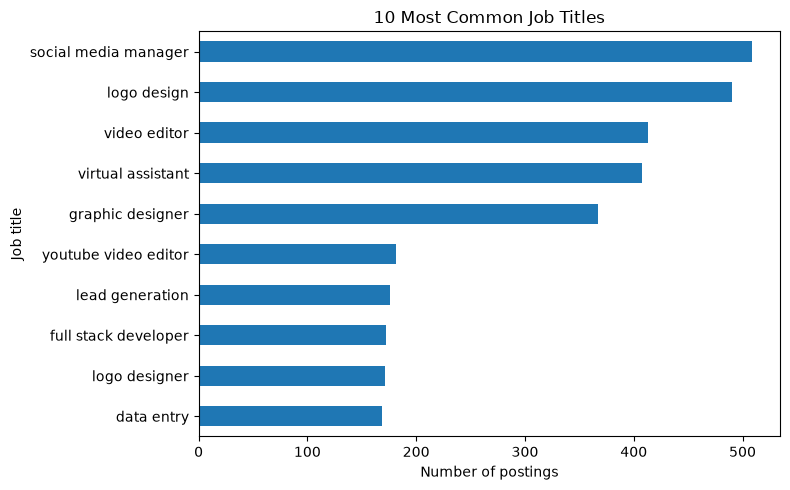

In [27]:
import matplotlib.pyplot as plt

top_titles = (
    jobs_clean["title"]
    .str.strip()
    .str.lower()
    .value_counts()
    .head(10)
)

top_titles.sort_values().plot(kind="barh", figsize=(8, 5))

plt.title("10 Most Common Job Titles")
plt.xlabel("Number of postings")
plt.ylabel("Job title")
plt.tight_layout()
plt.show()

In [28]:
jobs_clean["country"].value_counts().head(10)

country
United States           99834
United Kingdom          19149
India                   15835
Australia               12618
Canada                  11658
Pakistan                 5291
Germany                  4844
Netherlands              4435
United Arab Emirates     4039
France                   3163
Name: count, dtype: int64

In [29]:
hourly_pay = jobs_clean.loc[
    jobs_clean["is_hourly"]
    & jobs_clean["hourly_low"].notna()
    & jobs_clean["hourly_high"].notna()
].copy()

hourly_pay["hourly_midpoint"] = (
    hourly_pay["hourly_low"] + hourly_pay["hourly_high"]
) / 2

print("Hourly postings with both rate bounds:", len(hourly_pay))

Hourly postings with both rate bounds: 98775


In [30]:
hourly_pay["hourly_midpoint"].describe()

count    98775.000000
mean        29.709263
std         30.488625
min          3.000000
25%         14.000000
50%         22.500000
75%         35.000000
max        998.500000
Name: hourly_midpoint, dtype: float64

In [31]:
hourly_pay_no_cap = hourly_pay[
    hourly_pay["hourly_high"] < 999
].copy()

print("All records — mean:", hourly_pay["hourly_midpoint"].mean())
print("All records — median:", hourly_pay["hourly_midpoint"].median())

print("Without 999 upper rates — mean:",
      hourly_pay_no_cap["hourly_midpoint"].mean())
print("Without 999 upper rates — median:",
      hourly_pay_no_cap["hourly_midpoint"].median())

All records — mean: 29.709263477600608
All records — median: 22.5
Without 999 upper rates — mean: 29.53047903585173
Without 999 upper rates — median: 22.5


In [32]:
country_rates = (
    hourly_pay_no_cap
    .groupby("country")["hourly_midpoint"]
    .agg(["count", "mean", "median"])
    .sort_values("count", ascending=False)
)

country_rates.head(10).round(2)

,count,mean,median
country,,,
United States,46606,32.43,25.00
United Kingdom,8111,29.37,22.50
Australia,5680,24.29,20.75
Canada,5051,26.62,22.50
India,4334,23.26,20.00
Germany,2022,27.66,24.00
Netherlands,1554,23.83,20.00
Pakistan,1379,24.98,20.00
United Arab Emirates,1226,26.59,22.50


Task 1.1: Prepare titles for keyword analysis

In [33]:
hourly_pay_no_cap["title_lower"] = (
    hourly_pay_no_cap["title"].str.lower()
)

hourly_pay_no_cap[
    ["title", "title_lower", "hourly_midpoint"]
].head()

,title,title_lower,hourly_midpoint
2,SMMA Bubble App,smma bubble app,20.0
7,need Portuguese writers who can understand and...,need portuguese writers who can understand and...,14.5
13,URGENT: Fix Emails Not Working on Discourse In...,urgent: fix emails not working on discourse in...,57.5
15,Web3 Full-stack Developer,web3 full-stack developer,40.0
18,"Website design, UI/UX Design","website design, ui/ux design",21.0


Task 1.2: Compare pay for common title keywords

In [34]:
keywords = [
    "developer",
    "designer",
    "assistant",
    "video",
    "marketing",
    "data",
    "social media"
]

keyword_results = []

for keyword in keywords:
    matches = hourly_pay_no_cap[
        hourly_pay_no_cap["title_lower"].str.contains(
            keyword, na=False, regex=False
        )
    ]

    keyword_results.append({
        "keyword": keyword,
        "postings": len(matches),
        "average_midpoint": matches["hourly_midpoint"].mean(),
        "median_midpoint": matches["hourly_midpoint"].median()
    })

keyword_salary = pd.DataFrame(keyword_results)
keyword_salary.round(2)

,keyword,postings,average_midpoint,median_midpoint
0,developer,7716,29.66,25.0
1,designer,5692,27.86,25.0
2,assistant,3925,13.40,9.0
3,video,5409,26.68,20.0
4,marketing,4436,27.83,20.0
5,data,3466,24.99,20.0
6,social media,3657,19.84,16.5


Task 1.3: Compare Estimated Hourly Pay by Title Keyword

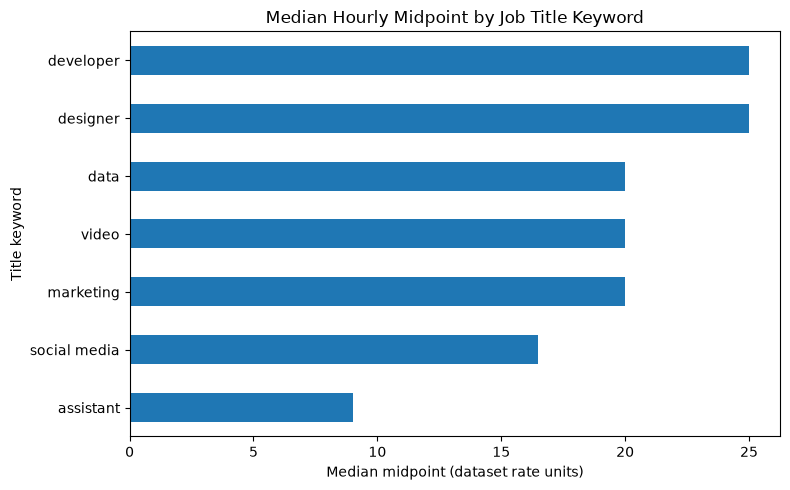

In [35]:
keyword_salary.set_index("keyword")["median_midpoint"].sort_values().plot(
    kind="barh",
    figsize=(8, 5)
)

plt.title("Median Hourly Midpoint by Job Title Keyword")
plt.xlabel("Median midpoint (dataset rate units)")
plt.ylabel("Title keyword")
plt.tight_layout()
plt.show()

Task 1.4: Calculate the keyword–pay correlations

In [36]:
keyword_correlations = []

for keyword in keywords:
    has_keyword = hourly_pay_no_cap["title_lower"].str.contains(
        keyword, na=False, regex=False
    ).astype(int)

    correlation = has_keyword.corr(
        hourly_pay_no_cap["hourly_midpoint"]
    )

    keyword_correlations.append({
        "keyword": keyword,
        "correlation": correlation
    })

correlation_table = pd.DataFrame(keyword_correlations)
correlation_table.sort_values(
    "correlation", ascending=False
).round(3)

,keyword,correlation
0,developer,0.001
4,marketing,-0.013
1,designer,-0.014
3,video,-0.024
5,data,-0.030
6,social media,-0.066
2,assistant,-0.114


### Task 1 finding

The selected title keywords have weak correlations with estimated hourly midpoint rates. The strongest negative correlation is for “assistant” (-0.114), while “developer” is nearly zero (0.001). These are exploratory results: keyword groups can overlap, the currency is unspecified, and correlation does not show that a keyword causes a pay difference.

Task 2.1: Count Job Title Keywords by Month

In [37]:
trend_data = jobs_clean[["published_date", "title"]].copy()

trend_data["month"] = trend_data["published_date"].dt.strftime("%Y-%m")
trend_data["title_lower"] = trend_data["title"].str.lower()

monthly_keyword_counts = pd.DataFrame({
    keyword: trend_data.loc[
        trend_data["title_lower"].str.contains(
            keyword, na=False, regex=False
        )
    ].groupby("month").size()
    for keyword in keywords
}).fillna(0).astype(int)

monthly_keyword_counts

,developer,designer,assistant,video,marketing,data,social media
month,,,,,,,
2023-12,0,0,0,2,1,1,0
2024-01,5,4,8,3,2,5,4
2024-02,6673,5440,2894,6448,3418,3600,2868
2024-03,9644,7690,3832,9641,5026,4340,4210


Task 2.2: Compare Keyword Share of Monthly Postings

In [38]:
monthly_totals = trend_data.groupby("month").size()

monthly_keyword_counts = monthly_keyword_counts.reindex(
    monthly_totals.index,
    fill_value=0
)

monthly_keyword_share = (
    monthly_keyword_counts
    .div(monthly_totals, axis=0)
    .mul(100)
    .round(2)
)

monthly_keyword_share

,developer,designer,assistant,video,marketing,data,social media
month,,,,,,,
2023-11,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2023-12,0.00,0.00,0.00,20.00,10.00,10.00,0.00
2024-01,5.21,4.17,8.33,3.12,2.08,5.21,4.17
2024-02,6.55,5.34,2.84,6.33,3.35,3.53,2.81
2024-03,6.75,5.38,2.68,6.75,3.52,3.04,2.95


Task 2.3: Calculate the February-to-March change

In [39]:
share_change = (
    monthly_keyword_share.loc["2024-03"]
    - monthly_keyword_share.loc["2024-02"]
).sort_values(ascending=False)

share_change.rename("change_in_percentage_points").to_frame()

,change_in_percentage_points
video,0.42
developer,0.20
marketing,0.17
social media,0.14
designer,0.04
assistant,-0.16
data,-0.49


Task 2.4: Visualize February-to-March Keyword Share Changes

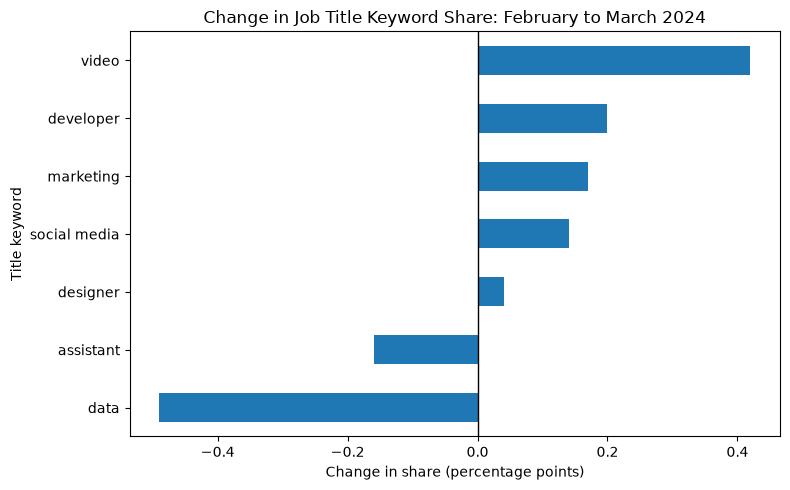

In [40]:
share_change.sort_values().plot(
    kind="barh",
    figsize=(8, 5)
)

plt.axvline(0, color="black", linewidth=1)
plt.title("Change in Job Title Keyword Share: February to March 2024")
plt.xlabel("Change in share (percentage points)")
plt.ylabel("Title keyword")
plt.tight_layout()
plt.show()

### Task 2 finding

Between February and March 2024, the selected job-title keyword shares changed only slightly. “Video” increased by 0.42 percentage points, while “data” decreased by 0.49 points. This analysis does not show strong evidence of an emerging category. The results are preliminary because the dataset has only two high-volume months; just 107 postings are dated before February. The keyword groups are based on job titles and may overlap.

Task 3.1: Build Daily Job-Demand Counts

In [41]:
trend_data["date"] = trend_data["published_date"].dt.normalize()

daily_keyword_counts = pd.DataFrame({
    keyword: trend_data.loc[
        trend_data["title_lower"].str.contains(
            keyword, na=False, regex=False
        )
    ].groupby("date").size()
    for keyword in keywords
}).fillna(0).astype(int)

all_dates = pd.date_range(
    start=trend_data["date"].min(),
    end=trend_data["date"].max(),
    freq="D"
)

daily_keyword_counts = daily_keyword_counts.reindex(
    all_dates,
    fill_value=0
)
daily_keyword_counts.index.name = "date"

print("Date range:", daily_keyword_counts.index.min(), "to",
      daily_keyword_counts.index.max())
print("Table size:", daily_keyword_counts.shape)

daily_keyword_counts.head()

Date range: 2023-11-02 00:00:00+00:00 to 2024-03-24 00:00:00+00:00
Table size: (144, 7)


,developer,designer,assistant,video,marketing,data,social media
date,,,,,,,
2023-11-02 00:00:00+00:00,0,0,0,0,0,0,0
2023-11-03 00:00:00+00:00,0,0,0,0,0,0,0
2023-11-04 00:00:00+00:00,0,0,0,0,0,0,0
2023-11-05 00:00:00+00:00,0,0,0,0,0,0,0
2023-11-06 00:00:00+00:00,0,0,0,0,0,0,0


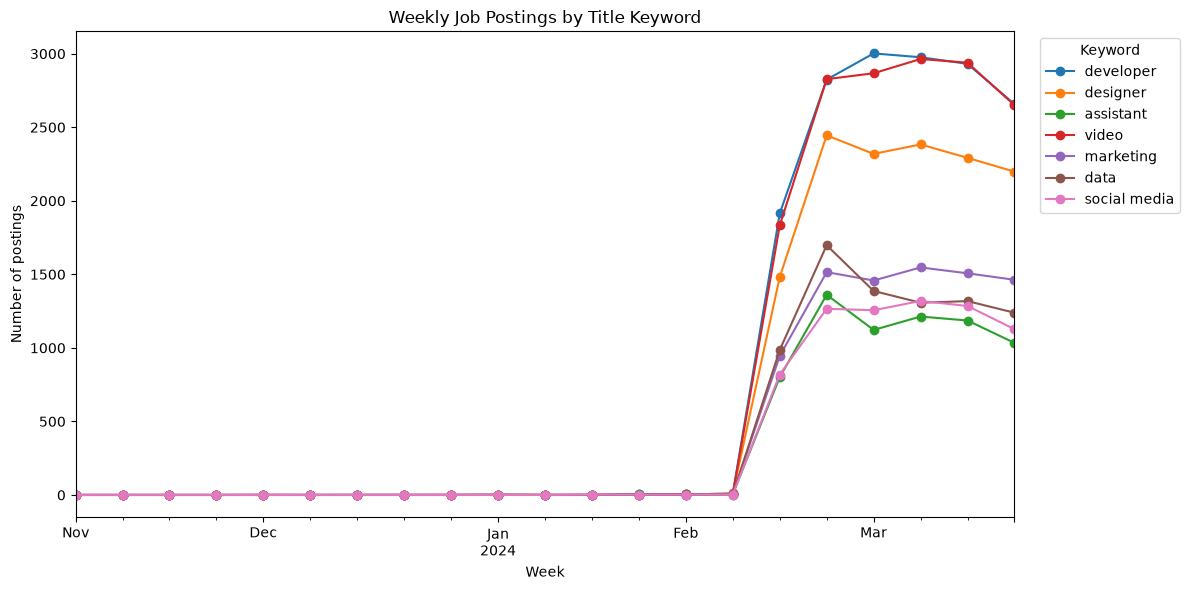

In [42]:
weekly_keyword_counts = daily_keyword_counts.resample("W").sum()

weekly_keyword_counts.plot(figsize=(12, 6), marker="o")
plt.title("Weekly Job Postings by Title Keyword")
plt.xlabel("Week")
plt.ylabel("Number of postings")
plt.legend(title="Keyword", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Task 3 Finding: Weekly Job Demand

The selected keyword counts are very low before February 2024 and rise sharply afterward. Developer and video-related titles have the highest weekly counts in the later period. Because the dataset has only a short high-volume history, this pattern is not enough to establish a reliable long-term demand trend or forecast. Keyword categories may also overlap.

In [43]:
country_pay = (
    hourly_pay_no_cap
    .groupby("country")["hourly_midpoint"]
    .agg(postings="count", mean_rate="mean", median_rate="median")
    .query("postings >= 500")
    .sort_values("median_rate", ascending=False)
)

country_pay.head(10).round(2)

,postings,mean_rate,median_rate
country,,,
Ukraine,569,30.33,25.0
United States,46606,32.43,25.0
Germany,2022,27.66,24.0
Switzerland,816,26.13,23.5
United Kingdom,8111,29.37,22.5
Canada,5051,26.62,22.5
Israel,770,26.60,22.5
United Arab Emirates,1226,26.59,22.5
Italy,504,26.87,22.5


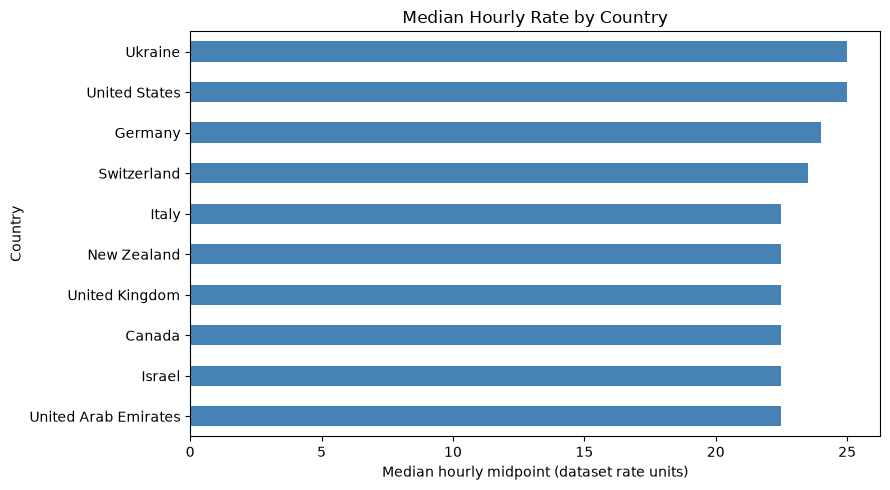

In [44]:
top_countries = country_pay.head(10).sort_values("median_rate")

top_countries["median_rate"].plot(
    kind="barh",
    figsize=(9, 5),
    color="steelblue"
)

plt.title("Median Hourly Rate by Country")
plt.xlabel("Median hourly midpoint (dataset rate units)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

### Task 4 Finding: Hourly Pay by Country

Among countries with at least 500 hourly listings, median hourly midpoints range from 22.5 to 25.0 dataset rate units. Ukraine and the United States have the highest median at 25.0, followed by Germany at 24.0. Posting counts vary substantially between countries, and the dataset does not specify a currency. These results should therefore be treated as descriptive comparisons, not as a measure of relative purchasing power.

## Conclusion and Limitations

The selected job-title keywords showed weak correlations with estimated hourly pay. Between February and March 2024, keyword shares changed only slightly. Weekly posting counts were much lower before February, so the short history does not support a reliable long-term demand forecast. Among countries with at least 500 hourly listings, median hourly midpoints ranged from 22.5 to 25.0 dataset rate units.

The dashboard demonstrates title-keyword job matching and summary statistics. Its recommendations match listing titles; they are not personalized predictions. The dataset does not specify currency and has no job descriptions, skills, or explicit remote-work field. These limitations restrict pay comparisons, remote-work analysis, and forecasting.